## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Pre Processing

In [2]:
df = pd.read_csv('anime_top_clean.csv', sep=",")
df

,title,type,episodes,score,members
0,Sousou no Frieren,TV,28.0,9.24,1540103
1,Fullmetal Alchemist: Brotherhood,TV,64.0,9.11,3753044
2,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,TV,19.0,9.07,367248
3,Steins;Gate,TV,24.0,9.07,2864729
4,Shingeki no Kyojin Season 3 Part 2,TV,10.0,9.06,2655133
...,...,...,...,...,...
195,Grand Blue,TV,12.0,8.45,934790
196,Mo Dao Zu Shi: Xian Yun Pian,ONA,8.0,8.45,120982
197,Owarimonogatari,TV,12.0,8.45,517694
198,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,Movie,1.0,8.45,654243


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   title     200 non-null    str    
 1   type      200 non-null    str    
 2   episodes  195 non-null    float64
 3   score     200 non-null    float64
 4   members   200 non-null    int64  
dtypes: float64(2), int64(1), str(2)
memory usage: 7.9 KB


In [4]:
df.describe()

,episodes,score,members
count,195.000000,200.000000,2.000000e+02
mean,18.738462,8.663850,8.001781e+05
std,27.038505,0.170009,8.742408e+05
min,1.000000,8.440000,3.657000e+03
25%,5.000000,8.520000,2.232040e+05
50%,12.000000,8.630000,4.600250e+05
75%,24.000000,8.752500,1.016888e+06
max,201.000000,9.240000,4.449420e+06


In [5]:
df.isna().sum()

title       0
type        0
episodes    5
score       0
members     0
dtype: int64

In [6]:
# Target (y) = 'type' (kategori)
# Setiap kelas mewakili format rilis anime:
#   TV      = serial televisi (biasanya 12-24+ episode)
#   Movie   = film layar lebar (umumnya 1 episode)
#   OVA     = Original Video Animation, rilis langsung ke video rumah
#   ONA     = Original Net Animation, rilis via internet/streaming
#   Special = episode spesial / bonus, biasanya menyertai seri utama
#   Unknown = tipe tidak diketahui / tidak dicantumkan di MAL
df['type'].unique()

<StringArray>
['TV', 'Movie', 'ONA', 'OVA', 'TV Special', 'Special']
Length: 6, dtype: str

In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['type'] = le.fit_transform(df['type'])
print(df['type'].unique())

for i, label in enumerate(le.classes_):
    print(f"{i} = {label}")

[4 0 1 2 5 3]
0 = Movie
1 = ONA
2 = OVA
3 = Special
4 = TV
5 = TV Special


In [8]:
df

,title,type,episodes,score,members
0,Sousou no Frieren,4,28.0,9.24,1540103
1,Fullmetal Alchemist: Brotherhood,4,64.0,9.11,3753044
2,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,4,19.0,9.07,367248
3,Steins;Gate,4,24.0,9.07,2864729
4,Shingeki no Kyojin Season 3 Part 2,4,10.0,9.06,2655133
...,...,...,...,...,...
195,Grand Blue,4,12.0,8.45,934790
196,Mo Dao Zu Shi: Xian Yun Pian,1,8.0,8.45,120982
197,Owarimonogatari,4,12.0,8.45,517694
198,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,0,1.0,8.45,654243


## Modelling

In [9]:
# Drop kolom yang tidak dipakai:
# - 'title' : teks bebas, bukan fitur numerik
# - 'type'  : sudah jadi target (y)
# Kolom numerik yang tersisa: episodes, members, score
x = df.drop(['title', 'type'], axis=1)
x

,episodes,score,members
0,28.0,9.24,1540103
1,64.0,9.11,3753044
2,19.0,9.07,367248
3,24.0,9.07,2864729
4,10.0,9.06,2655133
...,...,...,...
195,12.0,8.45,934790
196,8.0,8.45,120982
197,12.0,8.45,517694
198,1.0,8.45,654243


In [10]:
y = df['type']
y

0      4
1      4
2      4
3      4
4      4
      ..
195    4
196    1
197    4
198    0
199    1
Name: type, Length: 200, dtype: int64

In [11]:
# Sesuai ketentuan: x -> float64, y -> int64
# (scikit-learn sudah menangani pandas DataFrame, tapi ini eksplisit
#  supaya sesuai instruksi praktikum)
x = np.array(x, dtype=np.float64)
y = np.array(y, dtype=np.int64)

print("Shape x:", x.shape, "| dtype:", x.dtype)
print("Shape y:", y.shape, "| dtype:", y.dtype)

Shape x: (200, 3) | dtype: float64
Shape y: (200,) | dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

In [13]:
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier()
classifier.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

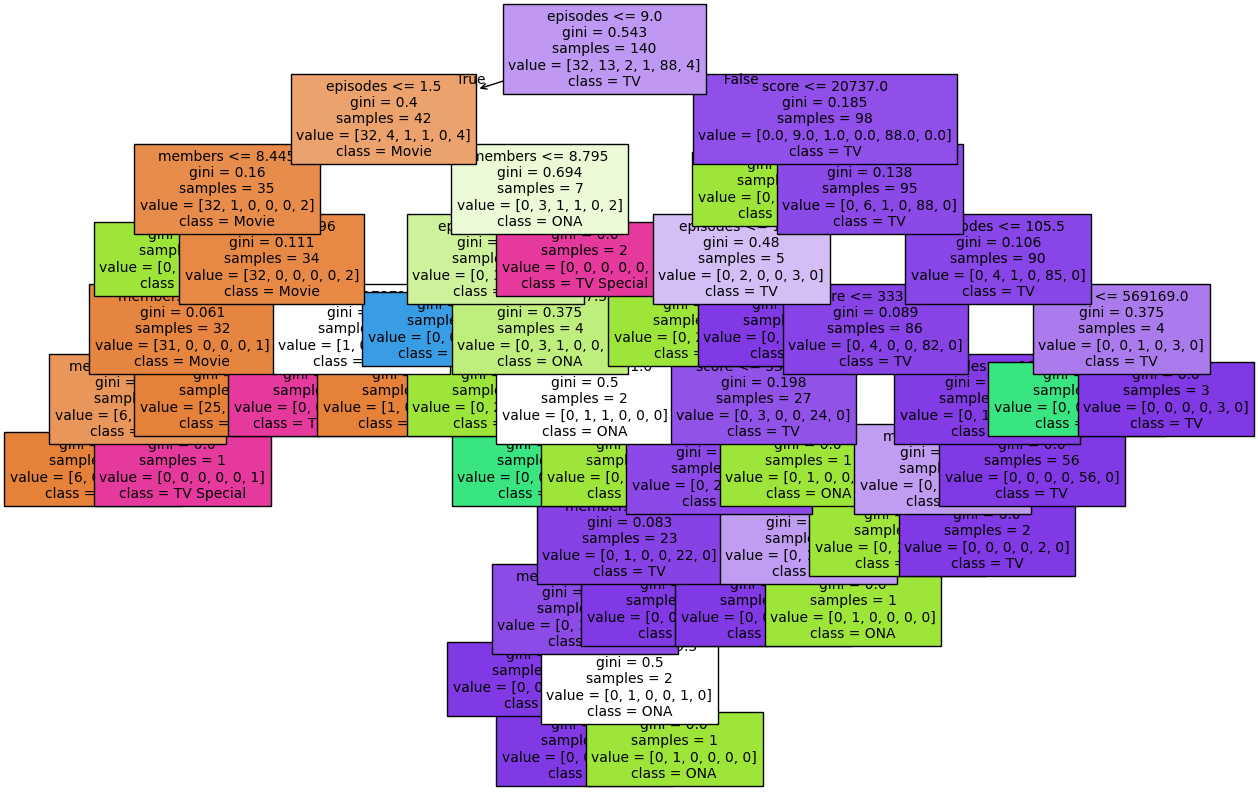

In [14]:
from sklearn import tree
# Maftuh Faisal_202431163
plt.subplots(figsize=(15, 10))
tree.plot_tree(
    classifier,
    feature_names=['episodes', 'members', 'score'],
    class_names=le.classes_.tolist(),
    filled=True,
    fontsize=10
)
plt.show()

In [15]:
depth = classifier.get_depth()
depth

10

In [16]:
from sklearn.metrics import accuracy_score

y_pred = classifier.predict(x_test)
akurasi = accuracy_score(y_test, y_pred)
print(akurasi)

0.8166666666666667


In [17]:
# Maftuh Faisal_202431163
y_pred_new = classifier.predict([[1, 500000, 8.5]])
print(y_pred_new)
print("Prediksi kelas:", le.inverse_transform(y_pred_new))

[5]
Prediksi kelas: ['TV Special']


In [19]:
from sklearn.metrics import classification_report
semua_label = range(len(le.classes_))
print(classification_report(
    y_test, 
    y_pred, 
    labels=semua_label,          
    target_names=le.classes_, 
    zero_division=0
))

              precision    recall  f1-score   support

       Movie       0.78      0.88      0.82         8
         ONA       0.40      0.25      0.31         8
         OVA       0.00      0.00      0.00         0
     Special       0.00      0.00      0.00         0
          TV       0.89      0.93      0.91        43
  TV Special       0.00      0.00      0.00         1

    accuracy                           0.82        60
   macro avg       0.34      0.34      0.34        60
weighted avg       0.79      0.82      0.80        60

